<a href="https://colab.research.google.com/github/Max-Sri-uttha/EPA-2026-2027/blob/main/CA1DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import sys, numpy as np, sklearn, tensorflow as tf
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.4.6
scikit-learn: 1.6.1
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Name:** Max Sri-uttha  
**Student Number:** X00213723

In [11]:
# Deep Learning and MLOps – CA1
Parameters: features = 69, random seed = 18, errors (flip_y) = 0.34, redundant = 17

SyntaxError: invalid syntax (508002498.py, line 2)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 18
np.random.seed(SEED)
tf.random.set_seed(SEED)


1. The task I have been given a dataset with 200,000 rows, each with 69 numbers and one label from 0 to 4. My job is to build a neural network that looks at the 69 numbers and predicts the label. Then I have to show my working: how I chose the network's design, how I tuned it, how I checked it wasn't over- or underfitting and how I saved and reused it. This is a multi-class classification problem (5 classes). The data is synthetic, generated with make_classification(). My labels are noisy(flip_y = 0.34). My aim is a network that generalises to unseen data, not just fits the training set.

2. Creating the dataset

In [13]:
features = 69
classes = 5
n = 200000
errors = 0.34
redundant = int(features / 4)   # 17

X, y = make_classification(n_samples=n, n_classes=classes, n_features=features,
                           random_state=SEED, n_informative=20,
                           flip_y=errors, n_redundant=redundant)
print(X.shape, y.shape, np.bincount(y))

(200000, 69) (200000,) [39959 40084 39991 39988 39978]


Missing values: 0
Feature means (first 5): [ 0.2  -0.   -0.   -0.41  0.09]
Feature std devs (first 5): [2.77 1.   1.   7.22 5.05]
Min / max overall: -43.34 43.91


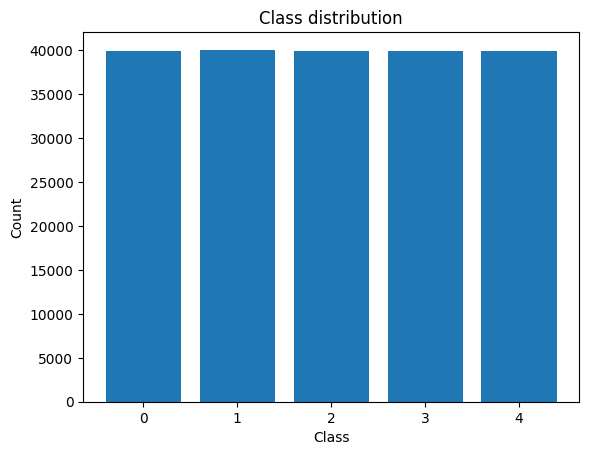

In [14]:
print("Missing values:", np.isnan(X).sum())
print("Feature means (first 5):", X.mean(axis=0)[:5].round(2))
print("Feature std devs (first 5):", X.std(axis=0)[:5].round(2))
print("Min / max overall:", X.min().round(2), X.max().round(2))

plt.bar(range(5), np.bincount(y))
plt.xlabel("Class"); plt.ylabel("Count"); plt.title("Class distribution")
plt.show()

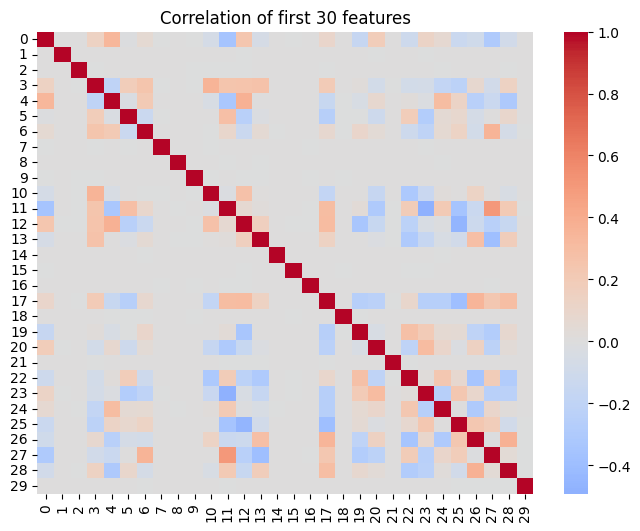

In [15]:
import seaborn as sns
corr = np.corrcoef(X[:, :30], rowvar=False)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation of first 30 features")
plt.show()